
# Employee Salary Prediction Using Linear Regression

### Predicting Employee Salaries Based on Years of Experience

## 1. Introduction

Salary prediction is a regression problem in machine learning that aims to estimate an employee's salary based on relevant information.

In this project, I use Python and Linear Regression to investigate the relationship between an employee's years of professional experience and their annual salary.

The project covers data loading, data cleaning, exploratory data analysis (EDA), data visualization, model development, prediction, and performance evaluation.

The main objective is to develop a simple, interpretable machine learning model that estimates salary based on years of experience.


## 2. Business Problem

Employee salaries often vary with professional experience. Understanding the relationship between experience and salary can help analyze salary trends and develop an initial salary estimation model.

The problem addressed in this project is:

**Can we predict an employee's annual salary based on their years of professional experience using Linear Regression?**

This project uses a simple dataset with experience and salary information to explore this relationship.


## 3. Project Objectives

The main objectives of this project are:

- Load and understand the dataset using Pandas.
- Inspect data types, missing values, and duplicate records.
- Perform data cleaning and validation.
- Conduct Exploratory Data Analysis (EDA).
- Visualize the relationship between experience and salary.
- Identify the independent and dependent variables.
- Split the dataset into training and testing sets.
- Build a Linear Regression model.
- Predict employee salaries using the trained model.
- Evaluate model performance using regression metrics.
- Interpret the results and identify potential improvements.


## 4. Dataset Description

The dataset used in this project is `Salary_Data.csv`.

It contains information about employees' years of professional experience and their corresponding salaries. Each row represents an employee record.

### Dataset Features

| Feature | Description | Type |
|---|---|---|
| YearsExperience | Years of professional experience | Numerical |
| Salary | Annual salary of the employee | Numerical |

### Variables

- **Independent variable (X):** YearsExperience
- **Dependent variable (y):** Salary

The objective is to learn the relationship between these variables and predict salary for previously unseen experience values.

The dataset's source and license should be documented in the repository before publication.


## 5. Import Libraries

The following Python libraries are used throughout this project:

- **Pandas:** Data loading, manipulation, and analysis.
- **NumPy:** Numerical computations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualization.
- **Scikit-learn:** Dataset splitting, Linear Regression, and model evaluation.

These libraries provide the tools needed to prepare the data, explore relationships, train the model, and evaluate its predictions.

In [2]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!



## 6. Load the Dataset

In this section, the employee salary dataset is loaded into a Pandas DataFrame using the `read_csv()` function.

Loading the dataset is the first step in data analysis. After loading the file, we will inspect its structure and verify that the data has been imported correctly.

The dataset contains two main variables:

- `YearsExperience`: The employee's years of professional experience.
- `Salary`: The employee's annual salary.

The dataset will be used to build a Linear Regression model that predicts salary based on years of experience.

In [3]:

# Load the dataset
df = pd.read_csv("Salary_Data.csv")

# Display a confirmation message
print("Dataset loaded successfully!")

Dataset loaded successfully!



## 7. Data Understanding

Data understanding is an important step in the machine learning workflow. It helps us inspect the dataset's structure, identify its features, and understand the values before performing data cleaning and exploratory data analysis.

In this section, we will:
- Display the first and last five records.
- Check the number of rows and columns.
- Inspect column names and data types.
- Examine non-null counts and memory usage.
- Calculate descriptive statistics for numerical variables.

These checks help us understand the dataset and identify any issues that need attention before model development.

In [4]:

# Display the first five rows
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [5]:

# Display the last five rows
df.tail()

,YearsExperience,Salary
25,9.0,105582.0
26,9.5,116969.0
27,9.6,112635.0
28,10.3,122391.0
29,10.5,121872.0


In [6]:

# Display the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 30
Number of columns: 2


In [7]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

Column names:
['YearsExperience', 'Salary']


In [8]:

# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [9]:

# Summary statistics for numerical columns
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000



## 8. Data Cleaning

Data cleaning is the process of identifying and handling missing values, duplicate records, incorrect data types, and invalid observations.

In this section, we will:
- Check for missing values.
- Count duplicate records.
- Verify the data types of each column.
- Check for non-numeric values.
- Identify invalid values, such as negative years of experience or non-positive salaries.

The dataset will be modified only when a genuine data quality issue is identified. This helps preserve valid observations and maintain data integrity.

In [10]:

# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

Missing values:
YearsExperience    0
Salary             0
dtype: int64


In [11]:

# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [12]:

# Check the data type of each column
print(df.dtypes)

YearsExperience    float64
Salary             float64
dtype: object


In [13]:

# Convert columns to numeric for validation
for col in ["YearsExperience", "Salary"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values after numeric validation:")
print(df[["YearsExperience", "Salary"]].isnull().sum())

Missing values after numeric validation:
YearsExperience    0
Salary             0
dtype: int64


In [14]:

# Check for invalid experience and salary values
print("Years of experience less than zero:",
      (df["YearsExperience"] < 0).sum())

print("Salary less than or equal to zero:",
      (df["Salary"] <= 0).sum())

Years of experience less than zero: 0
Salary less than or equal to zero: 0


In [15]:

# Remove rows with missing values in the required columns
df = df.dropna(subset=["YearsExperience", "Salary"]).copy()

# Retain valid experience and salary observations
df = df[
    (df["YearsExperience"] >= 0) &
    (df["Salary"] > 0)
].copy()

# Reset the row index
df.reset_index(drop=True, inplace=True)

print("Data cleaning completed.")
print("Final dataset shape:", df.shape)

Data cleaning completed.
Final dataset shape: (30, 2)


## 9. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of analyzing a dataset to understand its structure, distribution, patterns, and relationships between variables.

In this project, EDA will help us understand how years of experience are related to employee salaries. We will examine the dataset, analyze statistical summaries, and identify patterns that may help us predict salaries accurately.


In [16]:
print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (30, 2)

First five records:


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0



Statistical summary:


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [17]:
print("Years of Experience Analysis")
print("Minimum experience:", df["YearsExperience"].min())
print("Maximum experience:", df["YearsExperience"].max())
print("Average experience:", df["YearsExperience"].mean())
print("Median experience:", df["YearsExperience"].median())

Years of Experience Analysis
Minimum experience: 1.1
Maximum experience: 10.5
Average experience: 5.3133333333333335
Median experience: 4.7


In [18]:
print("Salary Analysis")
print("Minimum salary:", df["Salary"].min())
print("Maximum salary:", df["Salary"].max())
print("Average salary:", df["Salary"].mean())
print("Median salary:", df["Salary"].median())

Salary Analysis
Minimum salary: 37731.0
Maximum salary: 122391.0
Average salary: 76003.0
Median salary: 65237.0


In [19]:
correlation = df["YearsExperience"].corr(df["Salary"])

print("Correlation between Years of Experience and Salary:",
      round(correlation, 3))

Correlation between Years of Experience and Salary: 0.978


## 10. Data Visualization

Data visualization helps us understand patterns, distributions, and relationships in the dataset through graphical representations.

In this section, we will create:

* A histogram to examine the distribution of years of experience.
* A histogram to examine the distribution of salaries.
* Box plots to identify potential outliers.
* A scatter plot to visualize the relationship between years of experience and salary.

These visualizations will help us understand the dataset before building the Linear Regression model.


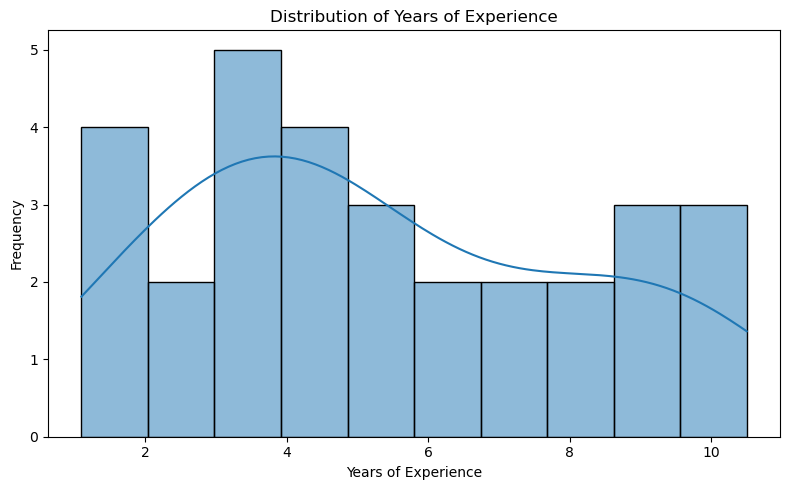

In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="YearsExperience", bins=10, kde=True)

plt.title("Distribution of Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

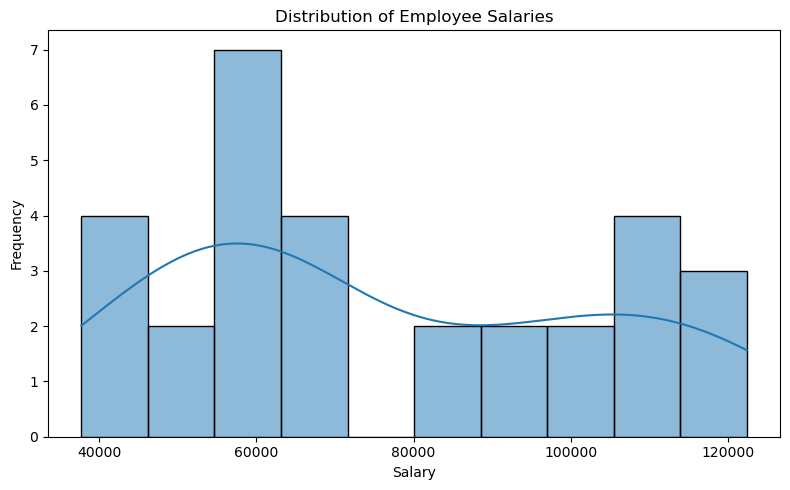

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Salary", bins=10, kde=True)

plt.title("Distribution of Employee Salaries")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

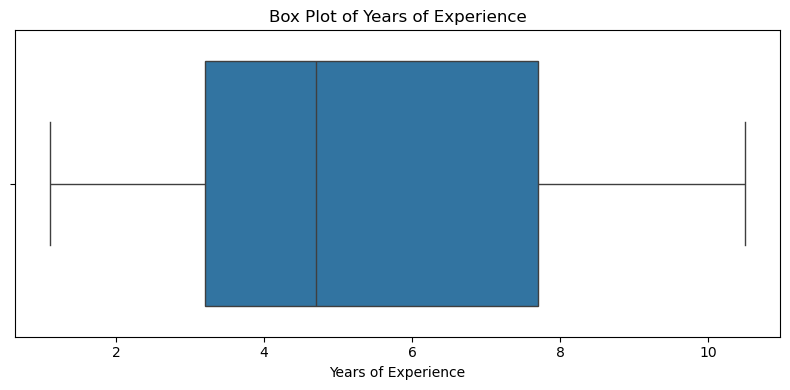

In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["YearsExperience"])

plt.title("Box Plot of Years of Experience")
plt.xlabel("Years of Experience")
plt.tight_layout()
plt.show()

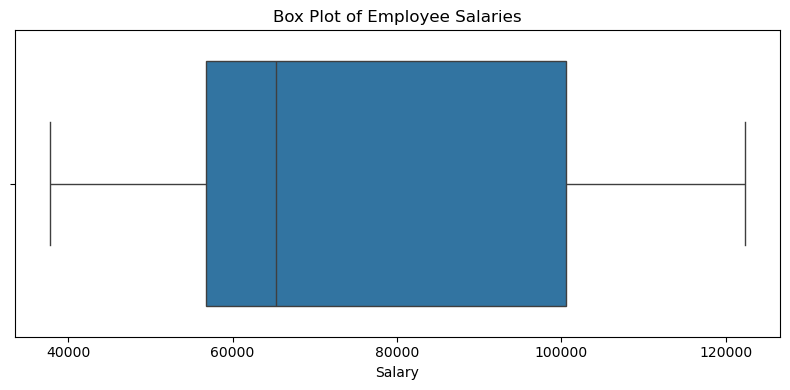

In [23]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Salary"])

plt.title("Box Plot of Employee Salaries")
plt.xlabel("Salary")
plt.tight_layout()
plt.show()

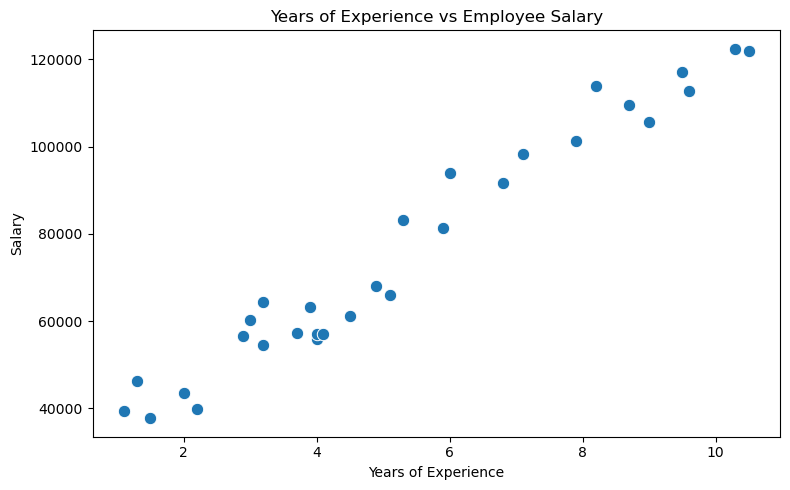

In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="YearsExperience",
    y="Salary",
    s=80
)

plt.title("Years of Experience vs Employee Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

### Visualization Insights

The scatter plot helps us examine the relationship between years of experience and employee salary. If the points generally move upward from left to right, it suggests that salaries tend to increase as experience increases.

The histograms show how experience and salary values are distributed, while the box plots help identify potential outliers. Potential outliers should be investigated rather than removed automatically.


## 11. Feature Selection

Feature selection involves identifying the input variable and target variable required for machine learning.

In this project:

* **Independent variable (X):** YearsExperience
* **Dependent variable (y):** Salary

The model will learn the relationship between years of experience and salary to predict an employee's salary based on their experience.


In [25]:
# Select the independent variable (feature)
X = df[["YearsExperience"]]

# Select the dependent variable (target)
y = df["Salary"]

print("Feature variable (X):")
display(X.head())

print("Target variable (y):")
display(y.head())

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Feature variable (X):


,YearsExperience
0,1.1
1,1.3
2,1.5
3,2.0
4,2.2


Target variable (y):


0    39343.0
1    46205.0
2    37731.0
3    43525.0
4    39891.0
Name: Salary, dtype: float64

Shape of X: (30, 1)
Shape of y: (30,)


## 12. Train-Test Split

Train-test splitting divides the dataset into training and testing sets.

* **Training set (80%):** Used to train the Linear Regression model.
* **Testing set (20%):** Used to evaluate the model on data it has not seen during training.

This helps us assess how well the model may perform on unseen data.


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (24, 1)
Testing features shape: (6, 1)
Training target shape: (24,)
Testing target shape: (6,)


## 13. Build the Linear Regression Model

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value by identifying the relationship between input and output variables.

In this project, the model uses YearsExperience as the independent variable and Salary as the dependent variable. It learns the relationship between these variables from the training data and uses that relationship to predict salaries for new observations.

The model estimates a straight-line relationship represented by:

**Salary = Intercept + (Coefficient × YearsExperience)**


In [27]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [28]:
# Get the model coefficient and intercept
coefficient = model.coef_[0]
intercept = model.intercept_

print("Coefficient:", round(coefficient, 2))
print("Intercept:", round(intercept, 2))

print(
    f"Salary = {intercept:.2f} + "
    f"({coefficient:.2f} × YearsExperience)"
)

Coefficient: 9423.82
Intercept: 25321.58
Salary = 25321.58 + (9423.82 × YearsExperience)


In [29]:
# Predict salaries using the test features
y_pred = model.predict(X_test)

print("Actual salaries:")
print(y_test.to_numpy())

print("\nPredicted salaries:")
print(np.round(y_pred, 2))

Actual salaries:
[112635.  67938. 113812.  83088.  64445.  57189.]

Predicted salaries:
[115790.21  71498.28 102596.87  75267.8   55477.79  60189.7 ]


## 14. Model Evaluation

Model evaluation helps us measure how accurately the Linear Regression model predicts employee salaries.

In this project, we will use four evaluation metrics:

* **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted salaries.
* **Mean Squared Error (MSE):** Measures the average squared prediction error.
* **Root Mean Squared Error (RMSE):** Represents the square root of MSE and expresses error in the same units as salary.
* **R² Score:** Measures how well the model explains the variation in salary values.

These metrics help us understand the prediction errors and the overall performance of the model on the test dataset.


In [33]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
-----------------------------------
Mean Absolute Error (MAE): 6286.45
Mean Squared Error (MSE): 49830096.86
Root Mean Squared Error (RMSE): 7059.04
R² Score: 0.9024


### Interpretation of Evaluation Metrics

* **MAE:** On average, predictions differ from actual salaries by the reported absolute error amount.
* **MSE:** Larger prediction errors receive greater weight because the errors are squared.
* **RMSE:** Estimates the typical prediction error magnitude and is expressed in the same units as salary.
* **R² Score:** A value closer to 1 generally indicates that the model explains more of the variation in the test-set salaries. A negative value means the model performs worse than predicting the test-set mean, as measured by R².

The evaluation results should be interpreted together. A lower MAE and RMSE generally indicate smaller prediction errors, while the R² score helps assess how much variation the model explains.


## 15. Actual vs. Predicted Salary

The Actual vs. Predicted plot compares actual salary values with the salaries predicted by the Linear Regression model. Points closer to the diagonal reference line indicate more accurate predictions.


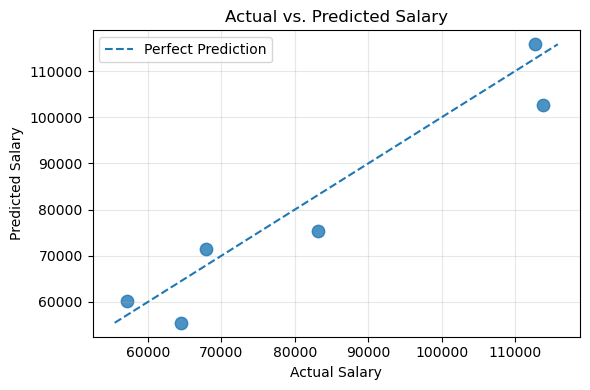

In [36]:
plt.figure(figsize=(6, 4))

plt.scatter(y_test, y_pred, s=80, alpha=0.8)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs. Predicted Salary")
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Residual Analysis

Residual analysis helps us understand the prediction errors made by the Linear Regression model.

A residual is the difference between an actual salary and its predicted salary.

**Residual = Actual Salary − Predicted Salary**

Residual analysis helps identify patterns in prediction errors and assess whether the model captures the relationship between years of experience and salary reasonably well.


In [37]:
# Calculate residuals
residuals = y_test.to_numpy() - y_pred

residual_df = pd.DataFrame({
    "Actual Salary": y_test.to_numpy(),
    "Predicted Salary": y_pred,
    "Residual": residuals
})

display(residual_df.round(2))

,Actual Salary,Predicted Salary,Residual
0,112635.0,115790.21,-3155.21
1,67938.0,71498.28,-3560.28
2,113812.0,102596.87,11215.13
3,83088.0,75267.80,7820.20
4,64445.0,55477.79,8967.21
5,57189.0,60189.70,-3000.70


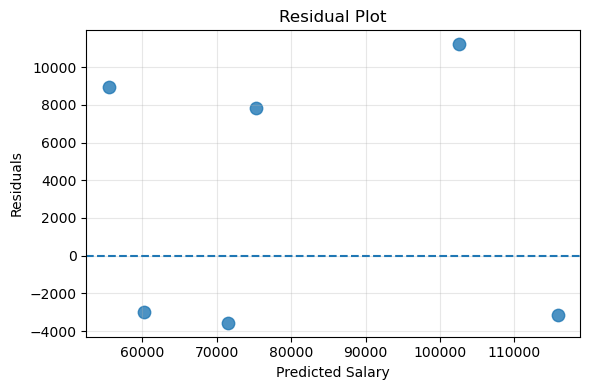

In [39]:
plt.figure(figsize=(6, 4))

plt.scatter(y_pred, residuals, s=80, alpha=0.8)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 17. Salary Prediction for New Employees

After training the model, we can use it to predict salaries for employees with new years-of-experience values. This demonstrates how the model can be applied to an example that was not part of the training dataset.


In [40]:
# Predict salary for employees with different experience levels
new_employees = pd.DataFrame({
    "YearsExperience": [1, 3, 5, 7, 10]
})

predicted_salaries = model.predict(new_employees)

new_employees["PredictedSalary"] = predicted_salaries

display(new_employees.round(2))

,YearsExperience,PredictedSalary
0,1,34745.40
1,3,53593.03
2,5,72440.66
3,7,91288.29
4,10,119559.74


## 18. Key Findings

1. The project explored the relationship between years of experience and employee salary.
2. Exploratory Data Analysis helped examine the distribution of both variables.
3. A Linear Regression model was trained using years of experience as the input feature and salary as the target variable.
4. Model performance was evaluated using MAE, MSE, RMSE, and the R² score.
5. The Actual vs. Predicted plot and residual analysis were used to examine prediction accuracy and errors.
6. The trained model can generate estimated salaries for new experience values.

The strength and accuracy of these findings should be interpreted using the actual evaluation results obtained from the test dataset.


## 19. Conclusion

In this project, an Employee Salary Prediction model was developed using Python and Linear Regression. The project covered data loading, data cleaning, exploratory data analysis, data visualization, feature selection, train-test splitting, model training, prediction, and evaluation.

The model uses years of experience to estimate employee salaries. Evaluation metrics and visualizations were used to understand its performance and prediction errors.

This project provided practical experience in data analysis and supervised machine learning. Future improvements could include using a larger dataset, testing additional relevant features, and comparing Linear Regression with other regression algorithms.
